# Golden Layer Analysis

This notebook uses the Golden Layer Analysis API to identify the optimal "golden layer" for model editing.

## Metrics:
- **Rewrite Accuracy**: Edit success on original prompt
- **Rephrase Accuracy**: Edit success on rephrased prompt
- **Locality**: Neighborhood preservation (post_neighborhood)
- **Portability**: One-hop reasoning (post_one_hop)
- **Overall**: Normalized average of all four metrics

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from golden_layer_api import GoldenLayerAnalyzer

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')

## 1. Initialize Analyzer and Load Data

In [2]:
# Create analyzer
analyzer = GoldenLayerAnalyzer(data_dir='../allLayerPerformance')

# Load data
analyzer.load_data(verbose=True)

Loading sample range 0-1037: samples 0-1036...

Loaded 1037 samples across 48 layers
  pre_rewrite: 49776/49776 non-NaN values
  pre_rephrase: 49776/49776 non-NaN values
  pre_one_hop: 49776/49776 non-NaN values
  post_rewrite: 49776/49776 non-NaN values
  post_rephrase: 49776/49776 non-NaN values
  post_neighborhood: 49776/49776 non-NaN values
  post_one_hop: 49776/49776 non-NaN values


## 2. Compute Overall Metric (Min-Max Normalized)

In [3]:
# Compute overall metric using min-max normalization
analyzer.compute_overall_metric(verbose=True)

Min-max normalized post_rewrite
Min-max normalized post_rephrase
Min-max normalized post_neighborhood
Min-max normalized post_one_hop

Computed post_overall metric: (1037, 48)
Non-NaN values: 49776 / 49776


## 3. Layer 17 (18th layer) Performance Analysis

In [4]:
import torch

# Analyze layer 17 (18th layer, 0-indexed)
layer_idx = 17

print(f"{'='*70}")
print(f"LAYER {layer_idx} PERFORMANCE ANALYSIS")
print(f"{'='*70}")

# For first 300 samples
print(f"\nFirst 300 samples (indices 0-299):")
for metric_key, metric_name in analyzer.metrics_info:
    layer_values = analyzer.results[metric_key][:300, layer_idx]
    valid_values = layer_values[~torch.isnan(layer_values)]
    if len(valid_values) > 0:
        mean_val = valid_values.mean().item()
        print(f"  {metric_name:20s}: {mean_val:.4f} (n={len(valid_values)})")
    else:
        print(f"  {metric_name:20s}: No valid data")

# For all 1037 samples
print(f"\nAll 1037 samples:")
for metric_key, metric_name in analyzer.metrics_info:
    layer_values = analyzer.results[metric_key][:, layer_idx]
    valid_values = layer_values[~torch.isnan(layer_values)]
    if len(valid_values) > 0:
        mean_val = valid_values.mean().item()
        print(f"  {metric_name:20s}: {mean_val:.4f} (n={len(valid_values)})")
    else:
        print(f"  {metric_name:20s}: No valid data")

LAYER 17 PERFORMANCE ANALYSIS

First 300 samples (indices 0-299):
  Rewrite Accuracy    : 0.9505 (n=300)
  Rephrase Accuracy   : 0.8393 (n=300)
  Locality            : 0.8609 (n=300)
  Portability         : 0.5003 (n=300)
  Overall             : 0.7949 (n=300)

All 1037 samples:
  Rewrite Accuracy    : 0.9477 (n=1037)
  Rephrase Accuracy   : 0.8299 (n=1037)
  Locality            : 0.8658 (n=1037)
  Portability         : 0.5021 (n=1037)
  Overall             : 0.7912 (n=1037)


## 4. Dataset Split: Proxy Set and Test Set

In [5]:
# Split dataset into proxy (100 samples) and test (937 samples)
analyzer.split_dataset(proxy_size=100, random_seed=42, verbose=True)


Dataset split:
  Total samples: 1037
  Proxy set: 100 samples
  Test set: 937 samples


## 5. Compute Proxy and Test Performance

In [6]:
# Compute average performance for proxy and test sets
analyzer.compute_proxy_test_means(verbose=True)

Rewrite Accuracy    : Computed proxy and test means
Rephrase Accuracy   : Computed proxy and test means
Locality            : Computed proxy and test means
Portability         : Computed proxy and test means
Overall             : Computed proxy and test means


In [7]:
# Display average performance statistics
print(f"\n{'='*70}")
print("AVERAGE PERFORMANCE: PROXY vs TEST")
print(f"{'='*70}")

for metric_key, metric_name in analyzer.metrics_info:
    proxy_avg = analyzer.proxy_means[metric_key].nanmean().item()
    test_avg = analyzer.test_means[metric_key].nanmean().item()
    
    print(f"\n{metric_name}:")
    print(f"  Proxy set (avg across all layers): {proxy_avg:.4f}")
    print(f"  Test set (avg across all layers):  {test_avg:.4f}")
    print(f"  Difference: {abs(proxy_avg - test_avg):.4f}")


AVERAGE PERFORMANCE: PROXY vs TEST

Rewrite Accuracy:
  Proxy set (avg across all layers): 0.8621
  Test set (avg across all layers):  0.8528
  Difference: 0.0093

Rephrase Accuracy:
  Proxy set (avg across all layers): 0.7902
  Test set (avg across all layers):  0.7756
  Difference: 0.0146

Locality:
  Proxy set (avg across all layers): 0.8222
  Test set (avg across all layers):  0.8214
  Difference: 0.0008

Portability:
  Proxy set (avg across all layers): 0.4736
  Test set (avg across all layers):  0.4633
  Difference: 0.0103

Overall:
  Proxy set (avg across all layers): 0.7293
  Test set (avg across all layers):  0.7217
  Difference: 0.0076


## 6. Analyze Best Layers and Correlations

In [8]:
# Perform complete analysis
results = analyzer.analyze(verbose=True)


Rewrite Accuracy:
  Proxy: Layers [27] (score: 0.9826)
  Test:  Layers [18] (score: 0.9763)
  Overlap: None
  Correlation: r = 0.9957, p = 3.4720e-49

Rephrase Accuracy:
  Proxy: Layers [39] (score: 0.9477)
  Test:  Layers [40] (score: 0.9294)
  Overlap: None
  Correlation: r = 0.9924, p = 1.6598e-43

Locality:
  Proxy: Layers [11] (score: 0.9838)
  Test:  Layers [11] (score: 0.9795)
  Overlap: [11]
  Correlation: r = 0.9891, p = 6.9038e-40

Portability:
  Proxy: Layers [23] (score: 0.5645)
  Test:  Layers [22] (score: 0.5480)
  Overlap: None
  Correlation: r = 0.9610, p = 2.6068e-27

Overall:
  Proxy: Layers [19] (score: 0.8526)
  Test:  Layers [18] (score: 0.8426)
  Overlap: None
  Correlation: r = 0.9940, p = 7.3149e-46


## 7. Visualizations: Bar Charts (Proxy vs Test)

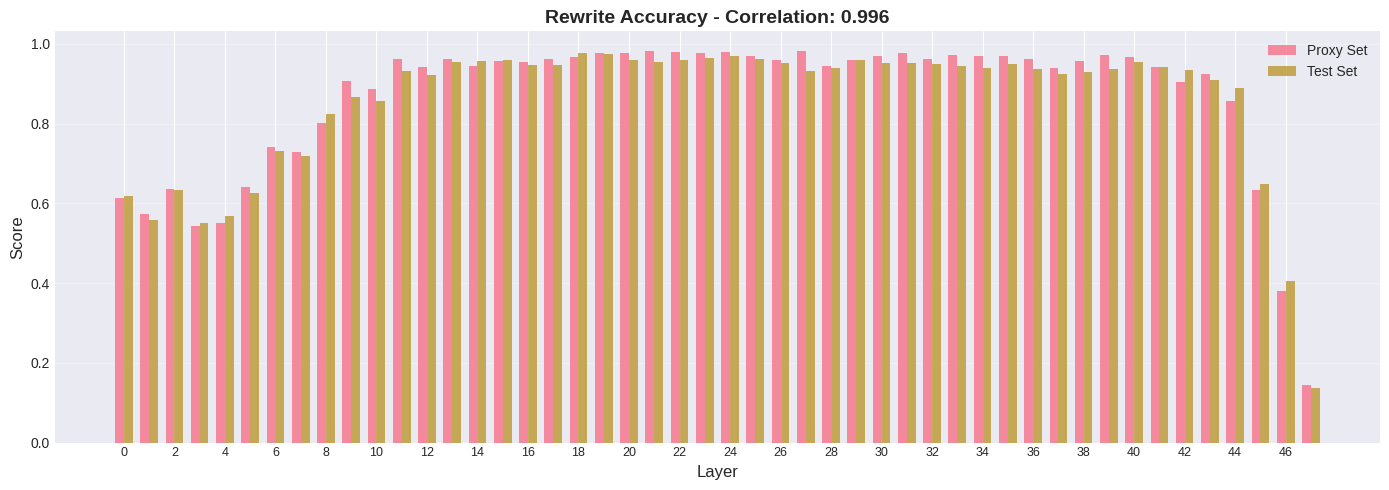

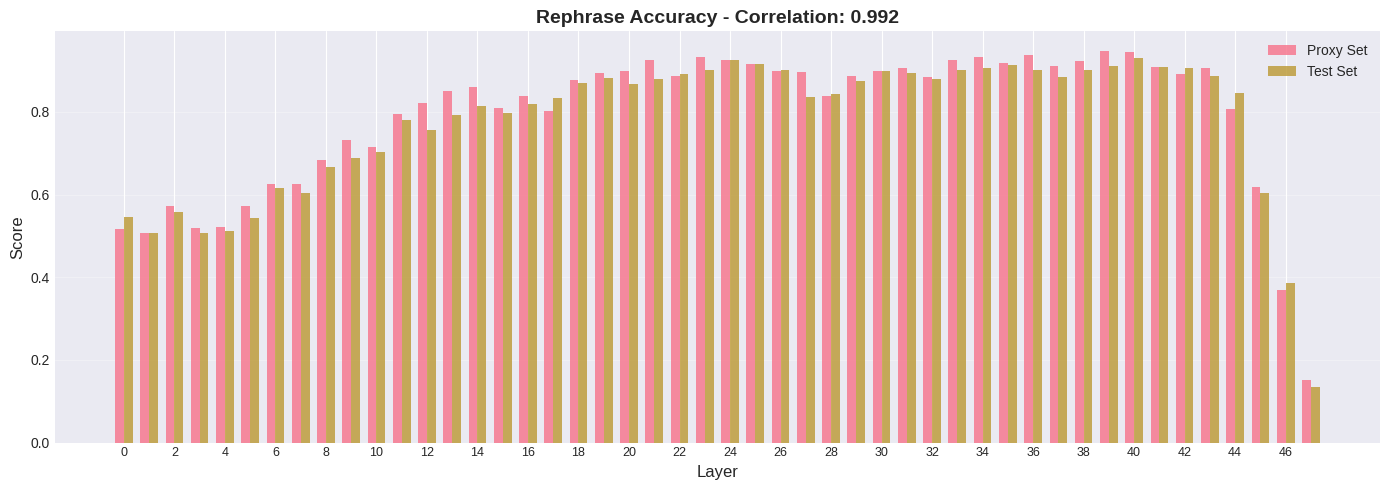

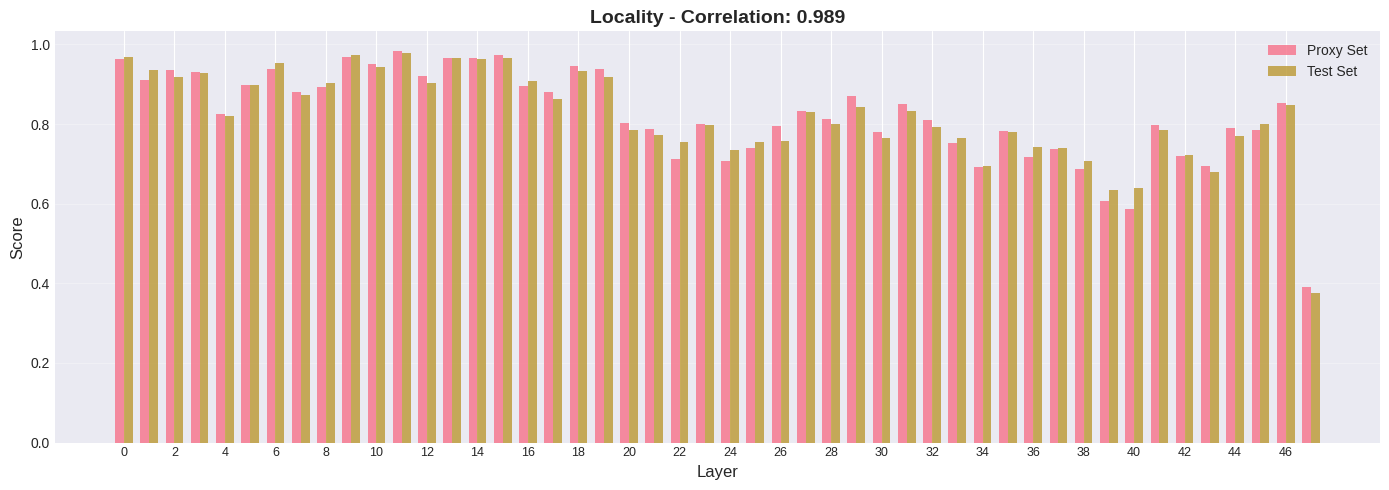

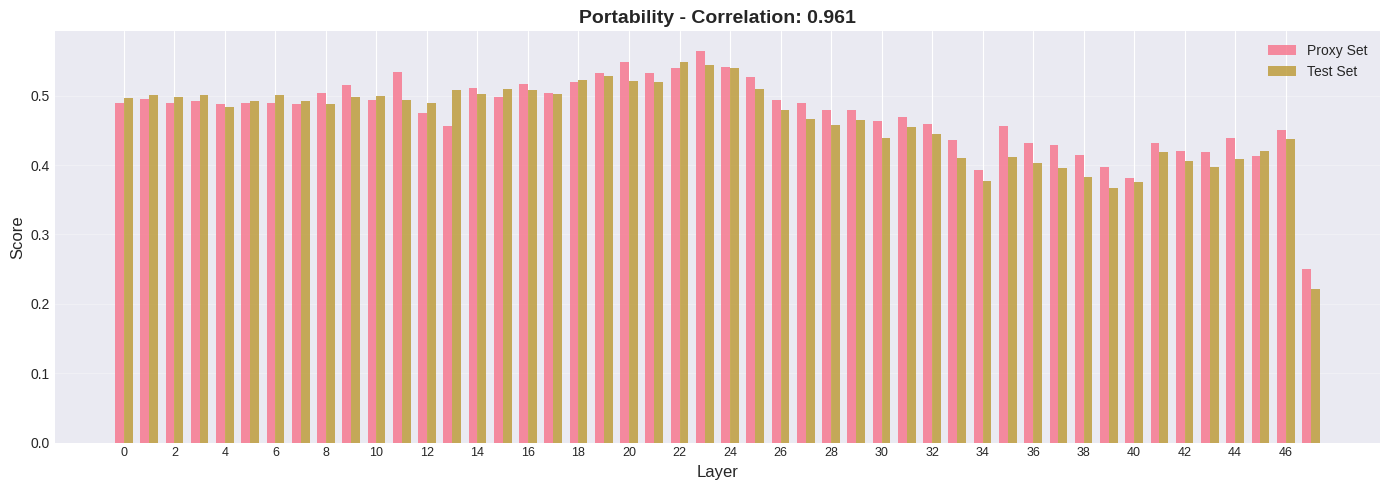

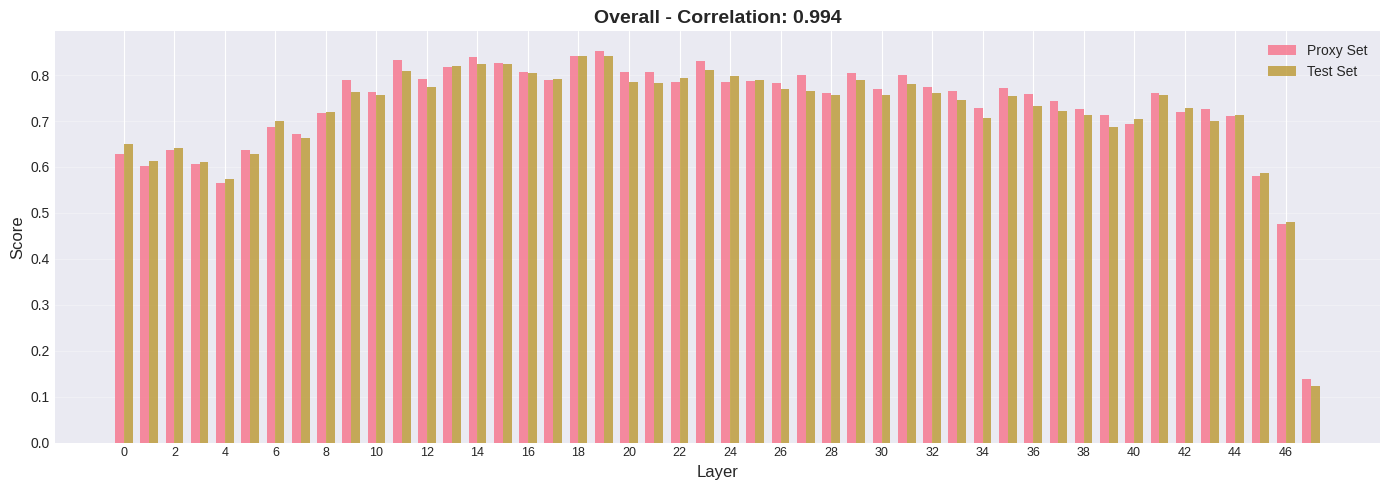

In [9]:
# Display bar charts inline (instead of saving)
for metric_key, metric_name in analyzer.metrics_info:
    fig, ax = plt.subplots(figsize=(14, 5))
    
    # Get layer-wise means for proxy and test
    proxy_layer_means = analyzer.proxy_means[metric_key].numpy()
    test_layer_means = analyzer.test_means[metric_key].numpy()
    
    # Get correlation
    correlation = analyzer.correlations_dict.get(metric_key, np.nan)
    
    # Create bar chart
    x = np.arange(analyzer.n_layers)
    width = 0.35
    
    ax.bar(x - width/2, proxy_layer_means, width, label='Proxy Set', alpha=0.8)
    ax.bar(x + width/2, test_layer_means, width, label='Test Set', alpha=0.8)
    
    ax.set_xlabel('Layer', fontsize=12)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_title(f'{metric_name} - Correlation: {correlation:.3f}',
                fontsize=14, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_xticks(range(0, analyzer.n_layers, 2))
    ax.set_xticklabels(range(0, analyzer.n_layers, 2), fontsize=9)
    
    plt.tight_layout()
    plt.show()

## 8. Summary Table (Metrics as Columns)

In [23]:
import pandas as pd

# Create summary table with metrics as columns
metric_names = [name for _, name in analyzer.metrics_info]
metric_keys = [key for key, _ in analyzer.metrics_info]

table_data = {
    'Metric': metric_names,
    'Correlation': [f"{analyzer.correlations_dict[key]:.4f}" if key in analyzer.correlations_dict else "N/A" 
                   for key in metric_keys],
    'Test score of Best layer selected by proxy': [f"{analyzer.test_means[key][analyzer.best_layers_comparison['post_overall']['proxy_best_layers'][0]].item():.4f}" if key in analyzer.test_means else "N/A"
                     for key in metric_keys],
    # 'Layer 5 Test': [f"{analyzer.test_means[key][5].item():.4f}" if key in analyzer.test_means else "N/A"
    #                  for key in metric_keys],
    'Test Score of Best Layer Selected by Test': [f"{analyzer.test_means[key][analyzer.best_layers_comparison['post_overall']['test_best_layers']][0].item():.4f}" if key in analyzer.test_means else "N/A"
                     for key in metric_keys],
    'Proxy Best Layers': [str(analyzer.best_layers_comparison[key]['proxy_best_layers']) 
                         for key in metric_keys],
    'Test Best Layers': [str(analyzer.best_layers_comparison[key]['test_best_layers']) 
                        for key in metric_keys],
    'Proxy Best Score': [f"{analyzer.best_layers_comparison[key]['proxy_best_value']:.4f}"
                        for key in metric_keys],
    'Test Best Score': [f"{analyzer.best_layers_comparison[key]['test_best_value']:.4f}"
                       for key in metric_keys],
    'Layer 17 Proxy': [f"{analyzer.proxy_means[key][17].item():.4f}"
                      for key in metric_keys],
    'Layer 17 Test': [f"{analyzer.test_means[key][19].item():.4f}"
                     for key in metric_keys],
}

# Add rows for performance at layers selected by each metric (for proxy set)
for selector_key, selector_name in analyzer.metrics_info:
    best_layers = analyzer.best_layers_comparison[selector_key]['proxy_best_layers']
    if best_layers:
        # Take first layer if there are ties
        layer = best_layers[0]
        row_name = f'{selector_name} Best Layer Proxy'
        table_data[row_name] = [f"{analyzer.proxy_means[metric_key][layer].item():.4f}"
                               for metric_key in metric_keys]

# Add rows for performance at layers selected by each metric (for test set)
for selector_key, selector_name in analyzer.metrics_info:
    best_layers = analyzer.best_layers_comparison[selector_key]['test_best_layers']
    if best_layers:
        # Take first layer if there are ties
        layer = best_layers[0]
        row_name = f'{selector_name} Best Layer Test'
        table_data[row_name] = [f"{analyzer.test_means[metric_key][layer].item():.4f}"
                               for metric_key in metric_keys]

df_summary = pd.DataFrame(table_data)
df_transposed = df_summary.set_index('Metric').T

print(f"\n{'='*70}")
print("SUMMARY TABLE")
print(f"{'='*70}\n")
print(df_transposed.to_string())
print()


SUMMARY TABLE

Metric                                     Rewrite Accuracy Rephrase Accuracy Locality Portability Overall
Correlation                                          0.9957            0.9924   0.9891      0.9610  0.9940
Test score of Best layer selected by proxy           0.9754            0.8825   0.9186      0.5281  0.8415
Test Score of Best Layer Selected by Test            0.9763            0.8693   0.9337      0.5223  0.8426
Proxy Best Layers                                      [27]              [39]     [11]        [23]    [19]
Test Best Layers                                       [18]              [40]     [11]        [22]    [18]
Proxy Best Score                                     0.9826            0.9477   0.9838      0.5645  0.8526
Test Best Score                                      0.9763            0.9294   0.9795      0.5480  0.8426
Layer 17 Proxy                                       0.9631            0.8016   0.8808      0.5043  0.7894
Layer 17 Test        

In [11]:
metric_names = [name for _, name in analyzer.metrics_info]
metric_keys = [key for key, _ in analyzer.metrics_info]

for key in metric_keys:
    print(key)

# for key in metric_keys:
key = "post_rewrite"
for layer in [27, 18, 38, 35]:
    print(f"{analyzer.test_means[key][layer].item():.4f}")
    # print(f"key-{key} layer-{layer}: {analyzer.test_means[key][layer].item():.4f}")

min = analyzer.test_means[key][0].item()
for layer in range(48):
    if min>analyzer.test_means[key][layer].item():
        min = analyzer.test_means[key][layer].item()
print(f"min: {min:.4f}")

post_rewrite
post_rephrase
post_neighborhood
post_one_hop
post_overall
0.9328
0.9763
0.9307
0.9504
min: 0.1382


In [12]:
metric_names = [name for _, name in analyzer.metrics_info]
metric_keys = [key for key, _ in analyzer.metrics_info]

for key in metric_keys:
    print(key)

# for key in metric_keys:
key = "post_rephrase"
for layer in [37, 38, 39, 40]:
    print(f"{analyzer.test_means[key][layer].item():.4f}")
    # print(f"key-{key} layer-{layer}: {analyzer.test_means[key][layer].item():.4f}")

min = analyzer.test_means[key][0].item()
for layer in range(48):
    if min>analyzer.test_means[key][layer].item():
        min = analyzer.test_means[key][layer].item()
print(f"min: {min:.4f}")

post_rewrite
post_rephrase
post_neighborhood
post_one_hop
post_overall
0.8854
0.9019
0.9108
0.9294
min: 0.1349


In [13]:
metric_names = [name for _, name in analyzer.metrics_info]
metric_keys = [key for key, _ in analyzer.metrics_info]

for key in metric_keys:
    print(key)

# for key in metric_keys:
key = "post_neighborhood"
for layer in [0, 9, 11]:
    print(f"{analyzer.test_means[key][layer].item():.4f}")
    # print(f"key-{key} layer-{layer}: {analyzer.test_means[key][layer].item():.4f}")

min = analyzer.test_means[key][0].item()
for layer in range(48):
    if min>analyzer.test_means[key][layer].item():
        min = analyzer.test_means[key][layer].item()
print(f"min: {min:.4f}")

post_rewrite
post_rephrase
post_neighborhood
post_one_hop
post_overall
0.9687
0.9725
0.9795
min: 0.3764


In [14]:
metric_names = [name for _, name in analyzer.metrics_info]
metric_keys = [key for key, _ in analyzer.metrics_info]

for key in metric_keys:
    print(key)

# for key in metric_keys:
key = "post_one_hop"
for layer in [23, 22, 0, 1]:
    print(f"{analyzer.test_means[key][layer].item():.4f}")
    # print(f"key-{key} layer-{layer}: {analyzer.test_means[key][layer].item():.4f}")

min = analyzer.test_means[key][0].item()
for layer in range(48):
    if min>analyzer.test_means[key][layer].item():
        min = analyzer.test_means[key][layer].item()
print(f"min: {min:.4f}")

post_rewrite
post_rephrase
post_neighborhood
post_one_hop
post_overall
0.5442
0.5480
0.4973
0.5007
min: 0.2218


## 9. Layer Performance Curves

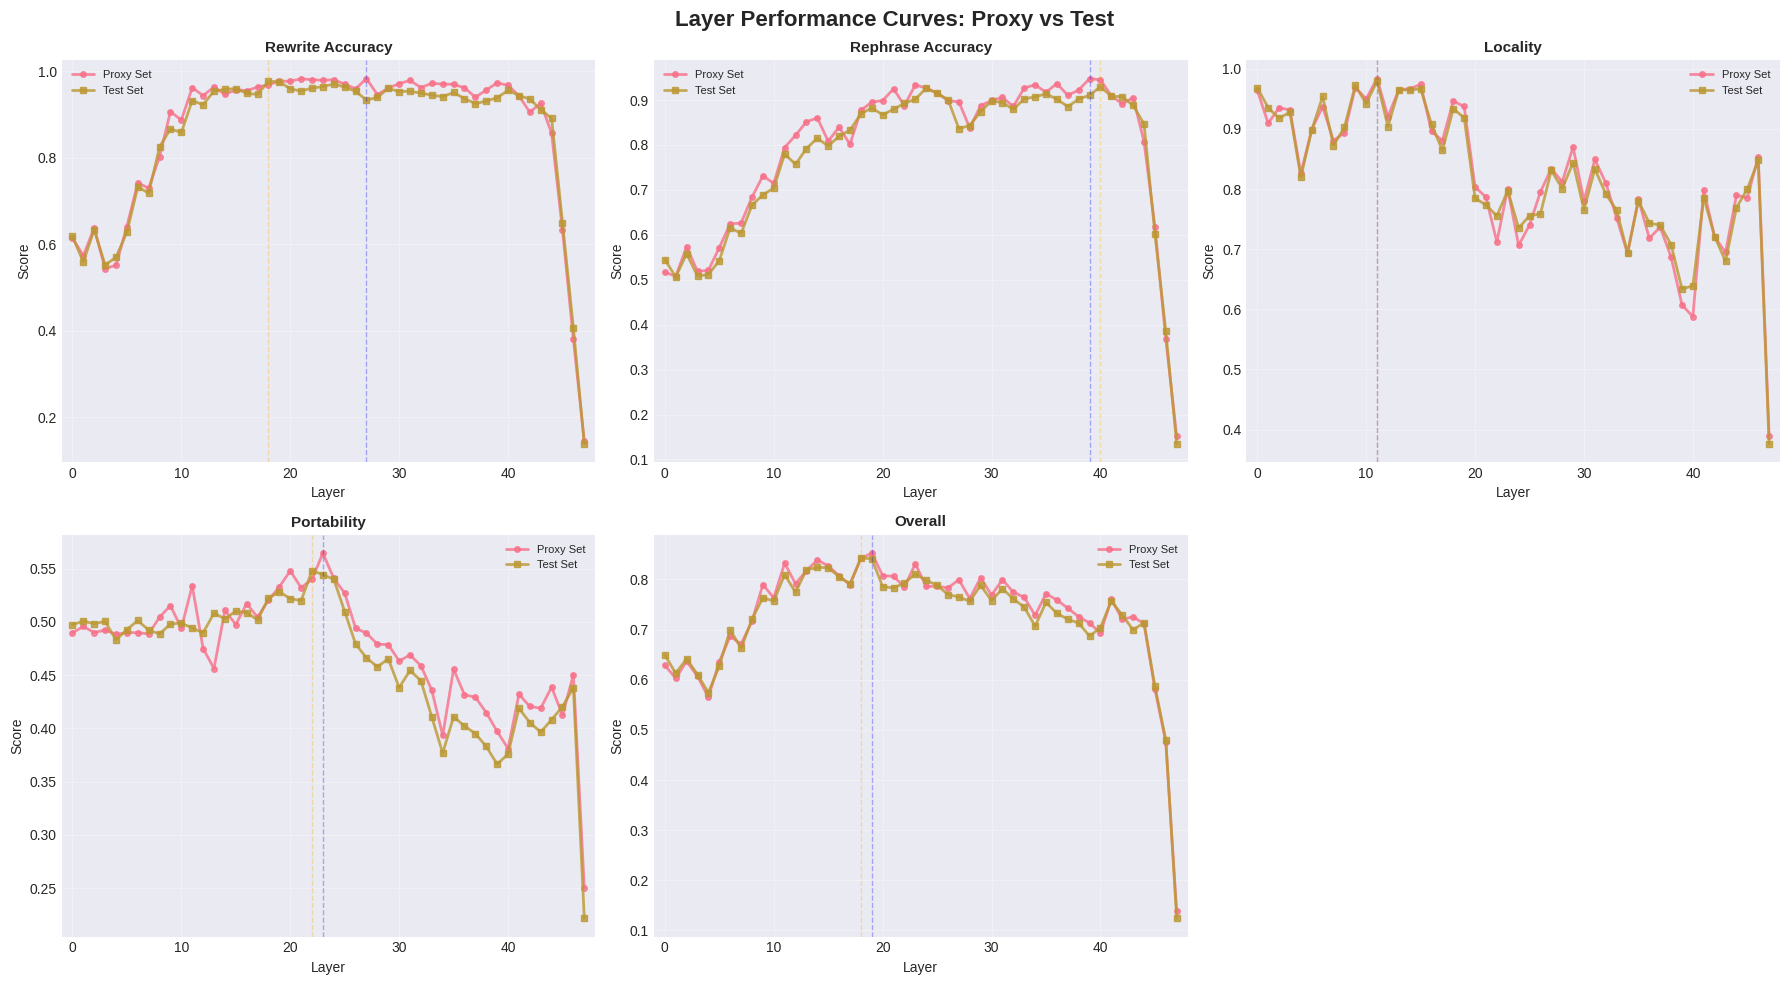

In [15]:
# Plot layer performance curves for proxy and test sets
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Layer Performance Curves: Proxy vs Test', fontsize=16, fontweight='bold')
axes = axes.flatten()

layers_array = np.arange(analyzer.n_layers)

for idx, (metric_key, metric_name) in enumerate(analyzer.metrics_info):
    ax = axes[idx]
    
    proxy_layer_means = analyzer.proxy_means[metric_key].numpy()
    test_layer_means = analyzer.test_means[metric_key].numpy()
    
    # Plot curves
    ax.plot(layers_array, proxy_layer_means, marker='o', linewidth=2, markersize=4, 
            label='Proxy Set', alpha=0.8)
    ax.plot(layers_array, test_layer_means, marker='s', linewidth=2, markersize=4, 
            label='Test Set', alpha=0.8)
    
    # Mark best layers
    if metric_key in analyzer.best_layers_comparison:
        info = analyzer.best_layers_comparison[metric_key]
        # Mark all proxy best layers
        for layer in info['proxy_best_layers']:
            ax.axvline(layer, color='blue', linestyle='--', alpha=0.3, linewidth=1)
        # Mark all test best layers
        for layer in info['test_best_layers']:
            ax.axvline(layer, color='orange', linestyle='--', alpha=0.3, linewidth=1)
    
    ax.set_xlabel('Layer', fontsize=10)
    ax.set_ylabel('Score', fontsize=10)
    ax.set_title(metric_name, fontsize=11, fontweight='bold')
    ax.legend(loc='best', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-1, analyzer.n_layers)

# Remove extra subplot
if len(analyzer.metrics_info) < 6:
    fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

## 10. Golden Layer Summary

In [16]:
# Print comprehensive summary using API method
analyzer.print_summary()


GOLDEN LAYER ANALYSIS SUMMARY

1. SUMMARY TABLE (Metrics as Columns):
Metric                             Rewrite Accuracy Rephrase Accuracy Locality Portability Overall
Correlation                                  0.9957            0.9924   0.9891      0.9610  0.9940
Proxy Best Layers                              [27]              [39]     [11]        [23]    [19]
Test Best Layers                               [18]              [40]     [11]        [22]    [18]
Proxy Best Score                             0.9826            0.9477   0.9838      0.5645  0.8526
Test Best Score                              0.9763            0.9294   0.9795      0.5480  0.8426
Layer 17 Proxy                               0.9631            0.8016   0.8808      0.5043  0.7894
Layer 17 Test                                0.9460            0.8330   0.8642      0.5019  0.7914
Rewrite Accuracy Best Layer Proxy            0.9826            0.8960   0.8341      0.4895  0.7995
Rephrase Accuracy Best Layer Proxy    

## 11. Agreement Analysis

In [17]:
print(f"\n{'='*70}")
print("AGREEMENT ANALYSIS")
print(f"{'='*70}")

for metric_key, metric_name in analyzer.metrics_info:
    info = analyzer.best_layers_comparison[metric_key]
    overlap = info['overlap']
    proxy_layers = info['proxy_best_layers']
    test_layers = info['test_best_layers']
    
    if overlap:
        print(f"\n{metric_name}:")
        print(f"  ✓ MATCH! Common best layers: {overlap}")
    else:
        print(f"\n{metric_name}:")
        print(f"  ✗ NO MATCH")
        print(f"    Proxy: {proxy_layers}")
        print(f"    Test:  {test_layers}")


AGREEMENT ANALYSIS

Rewrite Accuracy:
  ✗ NO MATCH
    Proxy: [27]
    Test:  [18]

Rephrase Accuracy:
  ✗ NO MATCH
    Proxy: [39]
    Test:  [40]

Locality:
  ✓ MATCH! Common best layers: [11]

Portability:
  ✗ NO MATCH
    Proxy: [23]
    Test:  [22]

Overall:
  ✗ NO MATCH
    Proxy: [19]
    Test:  [18]


## 12. Save Results

In [18]:
# Save bar charts to files
analyzer.save_bar_charts(output_dir='./figures', dpi=150)

# Save all results
analyzer.save_results(output_dir='./results')

print("\nAll results saved successfully!")

Saved: figures/post_rewrite_comparison.png


Saved: figures/post_rephrase_comparison.png
Saved: figures/post_neighborhood_comparison.png
Saved: figures/post_one_hop_comparison.png
Saved: figures/post_overall_comparison.png
Saved: results/golden_layer_analysis.pt
Saved: results/golden_layer_summary_table.csv
Saved: results/golden_layer_detailed.csv

All results saved successfully!


## 13. Custom Analysis Examples

### Example: Analyze specific layers

In [19]:
# Analyze layers around the golden layer
layers_of_interest = [15, 16, 17, 18, 19, 20]

print(f"\n{'='*70}")
print(f"DETAILED ANALYSIS: Layers {layers_of_interest}")
print(f"{'='*70}")

for layer in layers_of_interest:
    print(f"\nLayer {layer}:")
    for metric_key, metric_name in analyzer.metrics_info:
        proxy_score = analyzer.proxy_means[metric_key][layer].item()
        test_score = analyzer.test_means[metric_key][layer].item()
        diff = abs(proxy_score - test_score)
        print(f"  {metric_name:20s}: Proxy={proxy_score:.4f}, Test={test_score:.4f}, Diff={diff:.4f}")


DETAILED ANALYSIS: Layers [15, 16, 17, 18, 19, 20]

Layer 15:
  Rewrite Accuracy    : Proxy=0.9572, Test=0.9596, Diff=0.0024
  Rephrase Accuracy   : Proxy=0.8086, Test=0.7978, Diff=0.0108
  Locality            : Proxy=0.9741, Test=0.9669, Diff=0.0071
  Portability         : Proxy=0.4974, Test=0.5101, Diff=0.0126
  Overall             : Proxy=0.8273, Test=0.8237, Diff=0.0036

Layer 16:
  Rewrite Accuracy    : Proxy=0.9543, Test=0.9484, Diff=0.0060
  Rephrase Accuracy   : Proxy=0.8396, Test=0.8194, Diff=0.0202
  Locality            : Proxy=0.8958, Test=0.9077, Diff=0.0119
  Portability         : Proxy=0.5171, Test=0.5087, Diff=0.0084
  Overall             : Proxy=0.8071, Test=0.8055, Diff=0.0016

Layer 17:
  Rewrite Accuracy    : Proxy=0.9631, Test=0.9460, Diff=0.0170
  Rephrase Accuracy   : Proxy=0.8016, Test=0.8330, Diff=0.0313
  Locality            : Proxy=0.8808, Test=0.8642, Diff=0.0166
  Portability         : Proxy=0.5043, Test=0.5019, Diff=0.0024
  Overall             : Proxy=0.7

### Example: Compare different proxy sizes

In [20]:
# Compare results with different proxy sizes
proxy_sizes = [50, 100, 200]

print(f"\n{'='*70}")
print("PROXY SIZE COMPARISON")
print(f"{'='*70}")

for proxy_size in proxy_sizes:
    # Create new analyzer for each proxy size
    temp_analyzer = GoldenLayerAnalyzer(data_dir='../allLayerPerformance')
    (temp_analyzer
        .load_data(verbose=False)
        .compute_overall_metric(verbose=False)
        .split_dataset(proxy_size=proxy_size, random_seed=42, verbose=False)
        .compute_proxy_test_means(verbose=False)
        .analyze(verbose=False))
    
    overall_info = temp_analyzer.best_layers_comparison['post_overall']
    print(f"\nProxy size: {proxy_size}")
    print(f"  Proxy best layers: {overall_info['proxy_best_layers']}")
    print(f"  Test best layers:  {overall_info['test_best_layers']}")
    print(f"  Overlap: {overall_info['overlap'] if overall_info['overlap'] else 'None'}")
    print(f"  Correlation: {overall_info['correlation']:.4f}")


PROXY SIZE COMPARISON



Proxy size: 50
  Proxy best layers: [11]
  Test best layers:  [18]
  Overlap: None
  Correlation: 0.9835

Proxy size: 100
  Proxy best layers: [19]
  Test best layers:  [18]
  Overlap: None
  Correlation: 0.9940

Proxy size: 200
  Proxy best layers: [19]
  Test best layers:  [18]
  Overlap: None
  Correlation: 0.9969


## API Usage Summary

This notebook uses the `GoldenLayerAnalyzer` API for:

1. **Data Loading**: `load_data()`
2. **Overall Metric Computation**: `compute_overall_metric()`
3. **Dataset Splitting**: `split_dataset()`
4. **Performance Calculation**: `compute_proxy_test_means()`
5. **Analysis**: `analyze()`
6. **Saving Results**: `save_bar_charts()` and `save_results()`
7. **Summary Printing**: `print_summary()`

For more details, see `golden_layer_api.py` and `README.md`.

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from tqdm import tqdm

proxy_sizes = list(range(1, 501))

proxy_best_layers_scalar = []
test_best_layers_scalar = []

for proxy_size in tqdm(proxy_sizes):
    temp_analyzer = GoldenLayerAnalyzer(data_dir='../allLayerPerformance')
    (temp_analyzer
        .load_data(verbose=False)
        .compute_overall_metric(verbose=False)
        .split_dataset(proxy_size=proxy_size, random_seed=42, verbose=False)
        .compute_proxy_test_means(verbose=False)
        .analyze(verbose=False))

    overall_info = temp_analyzer.best_layers_comparison['post_overall']

    # ---- FIX: reduce list → scalar using MODE ----
    proxy_layers = overall_info['proxy_best_layers']
    test_layers  = overall_info['test_best_layers']

    proxy_mode = Counter(proxy_layers).most_common(1)[0][0]
    test_mode  = Counter(test_layers).most_common(1)[0][0]

    proxy_best_layers_scalar.append(proxy_mode)
    test_best_layers_scalar.append(test_mode)

# ---- Plot ----
plt.figure(figsize=(12, 5))
plt.plot(proxy_sizes, proxy_best_layers_scalar, label='Proxy (mode)', linewidth=2)
plt.plot(proxy_sizes, test_best_layers_scalar, label='Test (mode)', linewidth=2)

plt.xlabel("Proxy Size")
plt.ylabel("Selected Layer (mode)")
plt.title("Stability of Selected Editing Layer vs Proxy Size")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


  1%|          | 5/500 [00:19<31:22,  3.80s/it]


KeyboardInterrupt: 

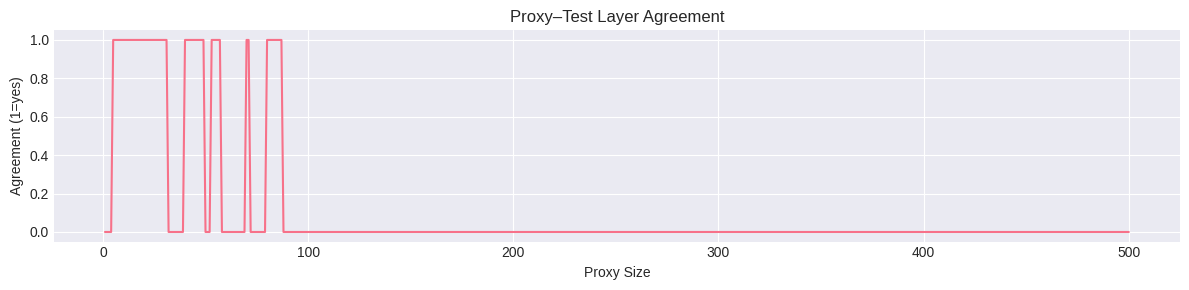

In [ ]:
agreement = np.array(proxy_best_layers_scalar) == np.array(test_best_layers_scalar)

plt.figure(figsize=(12, 3))
plt.plot(proxy_sizes, agreement.astype(int))
plt.xlabel("Proxy Size")
plt.ylabel("Agreement (1=yes)")
plt.title("Proxy–Test Layer Agreement")
plt.tight_layout()
plt.show()
